# MapleFreight Delivery Delay Prediction

**Project:** Predict whether an in-transit shipment will miss its promised delivery window and alert dispatch through Slack.

## 1. Imports and configuration



In [15]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    fbeta_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, precision_recall_curve
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_PATH = "maplefreight_delivery_delay_dataset.csv"
pd.set_option("display.max_columns", None)
warnings.filterwarnings("ignore", category=FutureWarning)

print("Libraries loaded.")

Libraries loaded.


## 2. Data understanding

Load the dataset and inspect the dimensions, data types, target distribution, missingness and duplicates. Record any unusual values for investigation rather than deleting them automatically.

In [16]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nData types and non-null counts:")
df.info()
print("\nSummary statistics:")
display(df.describe(include="all").T)
print("\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate shipment IDs:", df["shipment_id"].duplicated().sum())

Dataset shape: (6035, 23)


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,2,0,7.53,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,0,0,1.00,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,0,0,7.12,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,0,0,7.61,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,1,0,12.90,28.0,2.9,1.6,Clear,82.7,0.423,1,263.22,13.49,0



Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   str    
 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes      

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
shipment_id,6035,6000,SHP-102224,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_city,6035,7,Toronto ON,1593,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination_city,6035,10,Sudbury ON,641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carrier,6035,5,MapleFreight Fleet,2391,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_level,6035,6,Standard,3219,NaN,NaN,NaN,NaN,NaN,NaN,NaN
goods_type,6035,5,General Freight,2974,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_priority_tier,6035,3,Silver,2775,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipment_month,6035.0,NaN,NaN,NaN,6.543662,3.44826,1.0,4.0,7.0,10.0,12.0
distance_km,6035.0,NaN,NaN,NaN,632.192742,319.246133,80.5,398.6,571.1,804.85,2556.7
weight_kg,6035.0,NaN,NaN,NaN,6928.251135,83755.149685,30.0,496.0,827.1,1286.3,2999300.0



Missing values by column:


,missing_count
fuel_cost_cad,240
driver_experience_years,210
weather_condition,150
traffic_index,121
shipment_id,0
origin_city,0
destination_city,0
customer_priority_tier,0
goods_type,0
service_level,0



Exact duplicate rows: 32
Duplicate shipment IDs: 35


## 3. Exploratory data analysis (EDA)

Examine class balance, category-level late rates, and numeric differences between late and on-time shipments.

,count,percent
delivered_late,,
0,4793,79.42
1,1242,20.58


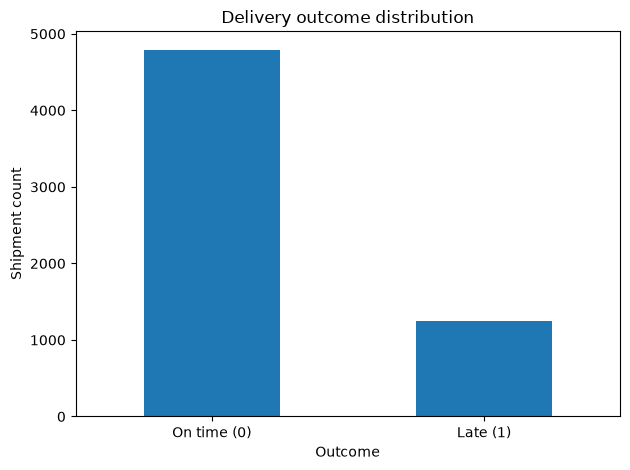

Always predicting on-time accuracy: 0.7942


In [17]:
target_counts = df["delivered_late"].value_counts().sort_index()
target_percent = (df["delivered_late"].value_counts(normalize=True).sort_index() * 100).round(2)
display(pd.DataFrame({"count": target_counts, "percent": target_percent}))

ax = target_counts.rename(index={0:"On time (0)", 1:"Late (1)"}).plot(
    kind="bar", rot=0, title="Delivery outcome distribution",
    xlabel="Outcome", ylabel="Shipment count"
)
plt.tight_layout()
plt.show()

print("Always predicting on-time accuracy:", round((df["delivered_late"] == 0).mean(), 4))

delivered_late,On time,Late
distance_km,602.27,747.67
weight_kg,6590.93,8230.02
num_stops,2.34,3.00
scheduled_transit_hours,10.00,12.45
pickup_delay_minutes,18.38,28.02
driver_experience_years,6.71,5.66
vehicle_age_years,5.38,5.91
traffic_index,53.66,60.88
route_congestion_score,0.44,0.49
prior_late_deliveries_30d,1.24,1.55


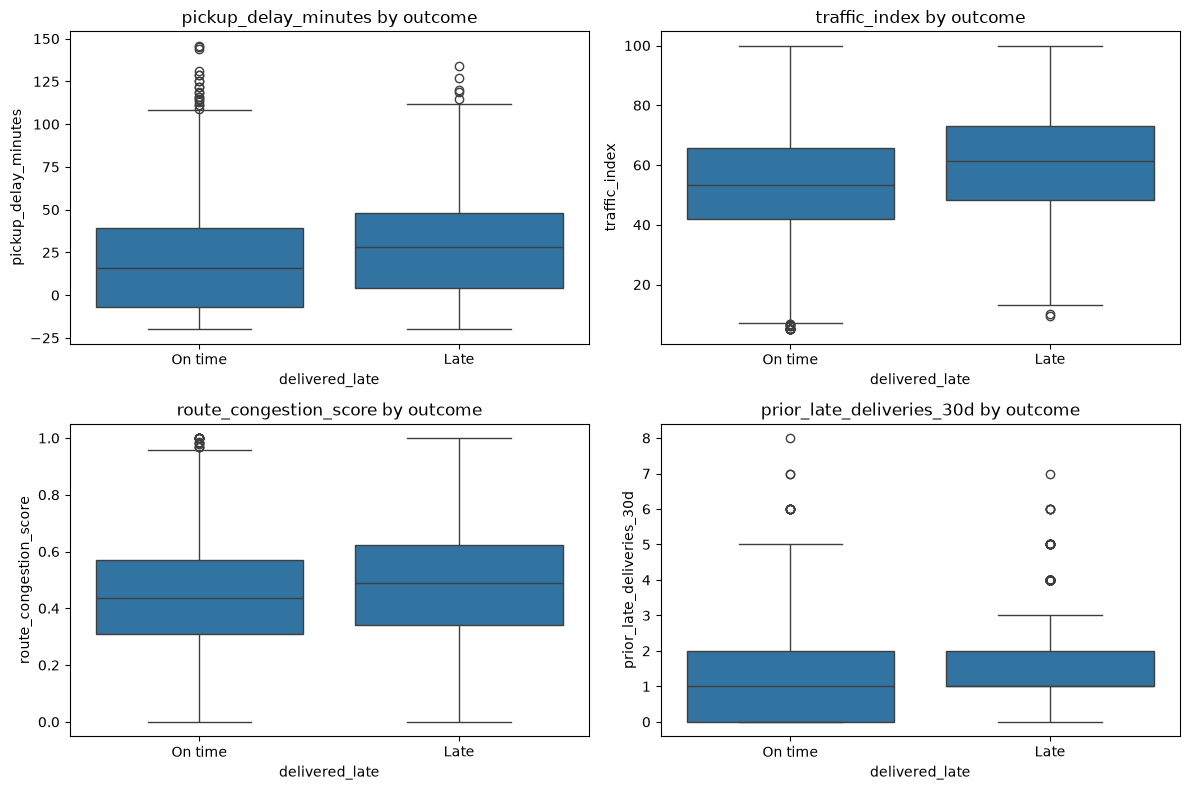

In [18]:
numeric_eda = [
    "distance_km", "weight_kg", "num_stops", "scheduled_transit_hours",
    "pickup_delay_minutes", "driver_experience_years", "vehicle_age_years",
    "traffic_index", "route_congestion_score", "prior_late_deliveries_30d",
    "fuel_cost_cad"
]
display(df.groupby("delivered_late")[numeric_eda].mean().T.rename(columns={0:"On time",1:"Late"}).round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), [
    "pickup_delay_minutes", "traffic_index",
    "route_congestion_score", "prior_late_deliveries_30d"
]):
    sns.boxplot(data=df, x="delivered_late", y=col, ax=ax)
    ax.set_xticks([0,1])
    ax.set_xticklabels(["On time","Late"])
    ax.set_title(f"{col} by outcome")
plt.tight_layout()
plt.show()

In [19]:
for col in ["carrier", "service_level", "goods_type", "weather_condition", "customer_priority_tier"]:
    summary = (df.groupby(col, dropna=False)["delivered_late"]
                 .agg(shipments="size", late_rate="mean")
                 .sort_values("late_rate", ascending=False))
    summary["late_rate_pct"] = (summary["late_rate"] * 100).round(2)
    print(f"Late rate by {col}")
    display(summary)

Late rate by carrier


,shipments,late_rate,late_rate_pct
carrier,,,
Contract Owner-Op,624,0.358974,35.90
PrairieLine,932,0.265021,26.50
QuebecExpress,924,0.224026,22.40
NorthStar Carriers,1164,0.219931,21.99
MapleFreight Fleet,2391,0.128816,12.88


Late rate by service_level


,shipments,late_rate,late_rate_pct
service_level,,,
Economy,1254,0.265550,26.56
economy,19,0.263158,26.32
express,27,0.222222,22.22
standard,74,0.216216,21.62
Standard,3219,0.206897,20.69
Express,1442,0.149792,14.98


Late rate by goods_type


,shipments,late_rate,late_rate_pct
goods_type,,,
Refrigerated,924,0.238095,23.81
Fragile,895,0.208939,20.89
General Freight,2974,0.204102,20.41
Hazardous,498,0.198795,19.88
Bulk,744,0.173387,17.34


Late rate by weather_condition


,shipments,late_rate,late_rate_pct
weather_condition,,,
Storm,285,0.463158,46.32
Snow,869,0.334868,33.49
NaN,150,0.220000,22.00
Fog,423,0.212766,21.28
Rain,1332,0.208709,20.87
Clear,2976,0.140457,14.05


Late rate by customer_priority_tier


,shipments,late_rate,late_rate_pct
customer_priority_tier,,,
Gold,1168,0.208048,20.80
Bronze,2092,0.206501,20.65
Silver,2775,0.204324,20.43


## 4. Data quality and preprocessing

This notebook removes exact duplicate rows, standardizes whitespace and case for text categories, checks repeated shipment IDs and flags implausible values. It does not blindly delete unusual weights or automatically merge repeated IDs; these need business validation.

In [20]:
# Remove exact duplicate rows only.
df = df.drop_duplicates().copy()

# Standardize text categories conservatively: strip whitespace and normalize case.
# This is suitable for the listed text categories; inspect unique values if local names have meaningful case.
cat_cols_raw = df.select_dtypes(include=["object"]).columns.tolist()
for col in cat_cols_raw:
    df[col] = df[col].map(lambda v: v.strip() if isinstance(v, str) else v)

for col in ["service_level", "goods_type", "customer_priority_tier", "weather_condition"]:
    df[col] = df[col].map(lambda v: v.title() if isinstance(v, str) else v)

print("Shape after exact duplicate removal:", df.shape)
print("Exact duplicate rows remaining:", df.duplicated().sum())
print("Repeated shipment IDs remaining:", df["shipment_id"].duplicated().sum())
display(df[df.duplicated("shipment_id", keep=False)].sort_values("shipment_id").head(20))

Shape after exact duplicate removal: (6003, 23)
Exact duplicate rows remaining: 2
Repeated shipment IDs remaining: 3


C:\Users\mahir\AppData\Local\Temp\ipykernel_15188\2002401113.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_raw = df.select_dtypes(include=["object"]).columns.tolist()


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
861,SHP-101906,Toronto ON,Edmonton AB,NorthStar Carriers,Express,General Freight,Bronze,7,333.7,1002.7,2,1,8.18,-20.0,10.0,3.8,Storm,27.9,0.320,2,261.21,8.00,0
3030,SHP-101906,Toronto ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,7,333.7,1002.7,2,1,8.18,-20.0,10.0,3.8,Storm,27.9,0.320,2,261.21,8.00,0
1228,SHP-102476,Toronto ON,Montreal QC,QuebecExpress,Standard,Hazardous,Silver,3,949.0,245.6,1,0,12.12,54.0,3.3,4.7,Storm,66.2,0.295,1,255.48,16.00,1
4033,SHP-102476,Toronto ON,Montreal QC,QuebecExpress,Standard,Hazardous,Silver,3,949.0,245.6,1,0,12.12,54.0,3.3,4.7,Storm,66.2,0.295,1,255.48,16.00,1
441,SHP-103022,Mississauga ON,Regina SK,Contract Owner-Op,Standard,General Freight,Bronze,1,404.4,570.1,2,0,7.42,-10.0,7.3,3.5,Snow,64.8,0.430,3,149.40,7.53,0
4375,SHP-103022,Mississauga ON,Regina SK,Contract Owner-Op,Standard,General Freight,Bronze,1,404.4,570.1,2,0,7.42,-10.0,7.3,3.5,Snow,64.8,0.430,3,149.40,7.53,0


In [21]:
# Flag values that deserve review; these are screening rules, not automatic deletion rules.
review_flags = {
    "weight_kg_over_100000": int((df["weight_kg"] > 100_000).sum()),
    "driver_experience_over_50_years": int((df["driver_experience_years"] > 50).sum()),
    "vehicle_age_over_40_years": int((df["vehicle_age_years"] > 40).sum()),
    "negative_distance": int((df["distance_km"] < 0).sum()),
    "nonpositive_scheduled_hours": int((df["scheduled_transit_hours"] <= 0).sum()),
}
print("Data quality review flags:")
display(pd.Series(review_flags, name="count").to_frame())
display(df.nlargest(10, "weight_kg")[["shipment_id","weight_kg","goods_type","distance_km"]])

Data quality review flags:


,count
weight_kg_over_100000,40
driver_experience_over_50_years,0
vehicle_age_over_40_years,0
negative_distance,0
nonpositive_scheduled_hours,0


,shipment_id,weight_kg,goods_type,distance_km
2323,SHP-102944,2999300.0,Hazardous,349.6
846,SHP-101687,1593600.0,General Freight,552.8
1525,SHP-102395,1554700.0,General Freight,418.2
3284,SHP-100634,1408300.0,General Freight,305.2
4761,SHP-104016,1389500.0,General Freight,577.9
696,SHP-100641,1332200.0,General Freight,843.1
4028,SHP-103017,1246100.0,General Freight,194.0
4876,SHP-104749,1238200.0,Fragile,519.3
4024,SHP-100891,1227100.0,Refrigerated,639.6
1030,SHP-102384,1209400.0,General Freight,944.6


## 5. Feature preparation and train/validation/test split

We exclude the shipment ID and `actual_transit_hours` to avoid identifier noise and target leakage. A stratified test set is held aside and is used only for final evaluation.

In [22]:
TARGET = "delivered_late"
excluded = ["shipment_id", "actual_transit_hours", TARGET]
X = df.drop(columns=excluded)
y = df[TARGET].astype(int)

# 20% untouched test set; remaining data split into training and validation.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=RANDOM_STATE, stratify=y_dev
)

print("Train:", X_train.shape, "Validation:", X_valid.shape, "Test:", X_test.shape)
print("Late rate train/validation/test:",
      round(y_train.mean(),3), round(y_valid.mean(),3), round(y_test.mean(),3))

numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features)
])
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Train: (3601, 20) Validation: (1201, 20) Test: (1201, 20)
Late rate train/validation/test: 0.206 0.206 0.206
Numeric features: ['shipment_month', 'distance_km', 'weight_kg', 'num_stops', 'is_cross_border', 'scheduled_transit_hours', 'pickup_delay_minutes', 'driver_experience_years', 'vehicle_age_years', 'traffic_index', 'route_congestion_score', 'prior_late_deliveries_30d', 'fuel_cost_cad']
Categorical features: ['origin_city', 'destination_city', 'carrier', 'service_level', 'goods_type', 'customer_priority_tier', 'weather_condition']


## 6. Baseline model

The DummyClassifier predicts the majority class and provides a useful minimum benchmark. We also fit logistic regression with class weighting as a stronger, interpretable baseline.

In [23]:
baseline = Pipeline([
    ("preprocess", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_valid)

logistic = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ))
])
logistic.fit(X_train, y_train)
logistic_valid_prob = logistic.predict_proba(X_valid)[:, 1]

def metrics_at_threshold(y_true, prob, threshold=0.5):
    pred = (np.asarray(prob) >= threshold).astype(int)
    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "F2": fbeta_score(y_true, pred, beta=2, zero_division=0)
    }

baseline_metrics = {
    "model": "Dummy majority-class",
    "accuracy": accuracy_score(y_valid, baseline_pred),
    "precision": precision_score(y_valid, baseline_pred, zero_division=0),
    "recall": recall_score(y_valid, baseline_pred, zero_division=0),
    "F1": f1_score(y_valid, baseline_pred, zero_division=0)
}
logistic_metrics = {"model":"Logistic regression (threshold 0.50)",
                    **metrics_at_threshold(y_valid, logistic_valid_prob, 0.5)}
display(pd.DataFrame([baseline_metrics, logistic_metrics]))

,model,accuracy,precision,recall,F1,threshold,F2
0,Dummy majority-class,0.794338,0.00000,0.000000,0.000000,NaN,NaN
1,Logistic regression (threshold 0.50),0.726062,0.41087,0.765182,0.534653,0.5,0.652624


## 7. Train and compare candidate models

A class-weighted Random Forest can capture nonlinear relationships and interactions. We compare it with logistic regression using validation F2, which places more emphasis on recall because missing a late shipment can be costly.

In [24]:
rf = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=350,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])
rf.fit(X_train, y_train)
rf_valid_prob = rf.predict_proba(X_valid)[:, 1]

candidate_results = []
for name, probs in [
    ("Logistic regression", logistic_valid_prob),
    ("Random Forest", rf_valid_prob)
]:
    row = {"model": name, **metrics_at_threshold(y_valid, probs, 0.5)}
    candidate_results.append(row)

display(pd.DataFrame(candidate_results).sort_values("F2", ascending=False))

,model,threshold,accuracy,precision,recall,F1,F2
0,Logistic regression,0.5,0.726062,0.410870,0.765182,0.534653,0.652624
1,Random Forest,0.5,0.815154,0.614679,0.271255,0.376404,0.305378


## 8. Select an alert threshold using validation data

The default threshold of 0.50 is not automatically best. Select a threshold using validation predictions only. Here we select the threshold that maximizes F2, which weights recall more heavily than precision. Review the resulting precision and alert volume with dispatch before production use.

In [25]:
candidate_models = {
    "Logistic regression": (logistic, logistic_valid_prob),
    "Random Forest": (rf, rf_valid_prob)
}
best_name, (best_model, best_valid_prob) = max(
    candidate_models.items(),
    key=lambda item: fbeta_score(
        y_valid, (item[1][1] >= 0.5).astype(int), beta=2, zero_division=0
    )
)

# Search thresholds on validation predictions, not test predictions.
threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.01):
    row = metrics_at_threshold(y_valid, best_valid_prob, round(float(threshold), 2))
    threshold_rows.append(row)
threshold_table = pd.DataFrame(threshold_rows)
best_row = threshold_table.loc[threshold_table["F2"].idxmax()]
ALERT_THRESHOLD = float(best_row["threshold"])

print("Selected model:", best_name)
print("Chosen validation threshold:", round(ALERT_THRESHOLD, 2))
display(best_row.to_frame("validation metric"))
display(threshold_table[threshold_table["threshold"].isin([0.3,0.4,0.5,0.6,0.7])])

Selected model: Logistic regression
Chosen validation threshold: 0.28


,validation metric
threshold,0.280000
accuracy,0.566195
precision,0.311813
recall,0.919028
F1,0.465641
F2,0.661422


,threshold,accuracy,precision,recall,F1,F2
20,0.3,0.580350,0.316166,0.894737,0.467230,0.655009
30,0.4,0.659450,0.358392,0.829960,0.500611,0.657051
40,0.5,0.726062,0.410870,0.765182,0.534653,0.652624
50,0.6,0.776020,0.467647,0.643725,0.541738,0.598645
60,0.7,0.811823,0.545455,0.510121,0.527197,0.516817


## 9. Final evaluation on the held-out test set

Report accuracy, precision, recall, F1 and the confusion matrix for the selected model at the chosen threshold. Also show the default 0.50 threshold for context.

,value
selected_model,Logistic regression
alert_threshold,0.28
accuracy,0.58035
precision,0.319776
recall,0.923077
F1,0.475
F2,0.670194


              precision    recall  f1-score   support

     On time       0.96      0.49      0.65       954
        Late       0.32      0.92      0.47       247

    accuracy                           0.58      1201
   macro avg       0.64      0.71      0.56      1201
weighted avg       0.83      0.58      0.61      1201



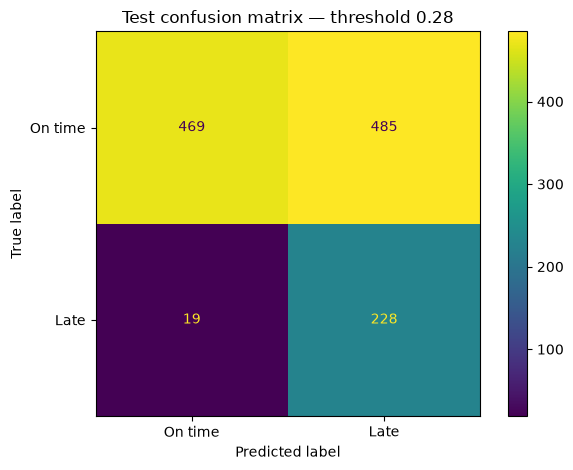

Confusion matrix [[TN, FP], [FN, TP]]:
[[469 485]
 [ 19 228]]


In [26]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= ALERT_THRESHOLD).astype(int)

final_metrics = {
    "selected_model": best_name,
    "alert_threshold": ALERT_THRESHOLD,
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "F2": fbeta_score(y_test, test_pred, beta=2, zero_division=0)
}
display(pd.DataFrame([final_metrics]).T.rename(columns={0:"value"}))

print(classification_report(y_test, test_pred, target_names=["On time", "Late"], zero_division=0))
cm = confusion_matrix(y_test, test_pred, labels=[0,1])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["On time","Late"]).plot(values_format="d")
plt.title(f"Test confusion matrix — threshold {ALERT_THRESHOLD:.2f}")
plt.tight_layout()
plt.show()

print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)

## 10. Model explainability

Permutation importance measures how much a metric degrades when a feature is shuffled on held-out data. It provides a model-agnostic view of which columns help prediction. Importance is associative, not proof of causation.

,feature,importance_mean,importance_std
15,weather_condition,0.069992,0.006996
9,num_stops,0.048327,0.006853
16,traffic_index,0.037527,0.014801
7,distance_km,0.032709,0.009897
2,carrier,0.026781,0.011735
13,driver_experience_years,0.023226,0.007915
12,pickup_delay_minutes,0.016569,0.006657
17,route_congestion_score,0.011172,0.007190
18,prior_late_deliveries_30d,0.005238,0.008930
6,shipment_month,0.005198,0.007779


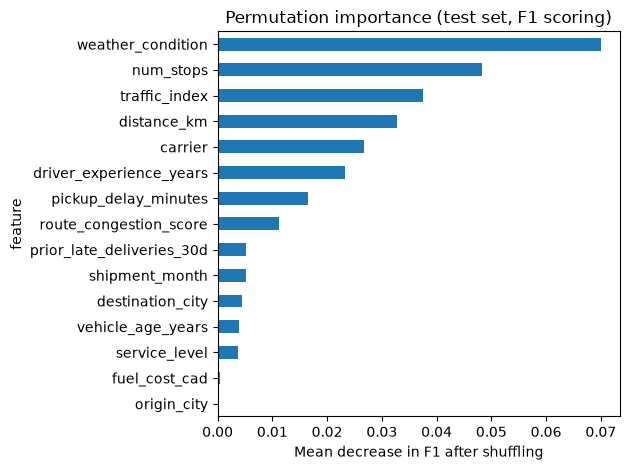

In [27]:
perm = permutation_importance(
    best_model, X_test, y_test,
    scoring="f1", n_repeats=5,
    random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance.head(15))
importance.head(15).sort_values("importance_mean").plot(
    x="feature", y="importance_mean", kind="barh", legend=False,
    title="Permutation importance (test set, F1 scoring)",
    xlabel="Mean decrease in F1 after shuffling"
)
plt.tight_layout()
plt.show()

## 11. Slack alert integration

In [28]:
# Optional dependency: python-dotenv and requests are listed in requirements.txt.
try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

import requests

webhook_url = os.getenv("SLACK_WEBHOOK_URL")

# Demonstration candidates from the held-out test split.
# Keep original metadata aligned to X_test's row indices.
risk_scores = pd.Series(test_prob, index=X_test.index, name="risk_score")
alerts = df.loc[X_test.index, [
    "shipment_id", "destination_city", "carrier"
]].copy()
alerts["risk_score"] = risk_scores
alerts = alerts[alerts["risk_score"] >= ALERT_THRESHOLD].sort_values(
    "risk_score", ascending=False
)

TOP_N = 5
print(f"High-risk shipments in this demonstration batch: {len(alerts)}")
display(alerts.head(TOP_N).assign(
    risk_score=lambda d: (d["risk_score"] * 100).round(1).astype(str) + "%"
))

if not webhook_url:
    print("Slack message NOT sent: set SLACK_WEBHOOK_URL in your local .env file.")
else:

    lines = [
        f"*MapleFreight dispatch alert — {len(alerts)} shipment(s) at high risk*",
        f"Alert threshold: {ALERT_THRESHOLD:.0%}",
        "Top at-risk shipments:"
    ]
    if alerts.empty:
        lines.append("No shipments exceed the current alert threshold.")
    else:
        for _, row in alerts.head(TOP_N).iterrows():
            lines.append(
                f"• ID: {row['shipment_id']} | Destination: {row['destination_city']} "
                f"| Carrier: {row['carrier']} | Risk: {row['risk_score']:.0%}"
            )
    response = requests.post(
        webhook_url,
        json={"text": "\n".join(lines)},
        timeout=15
    )
    response.raise_for_status()
    print("Slack webhook accepted the message (HTTP", response.status_code, ").")

High-risk shipments in this demonstration batch: 713


,shipment_id,destination_city,carrier,risk_score
1557,SHP-103230,Regina SK,Contract Owner-Op,98.5%
956,SHP-101710,Sudbury ON,MapleFreight Fleet,98.3%
3645,SHP-100273,Hamilton ON,NorthStar Carriers,98.2%
554,SHP-103300,Winnipeg MB,NorthStar Carriers,97.9%
940,SHP-101673,Sudbury ON,Contract Owner-Op,97.6%


Slack webhook accepted the message (HTTP 200 ).
